### In this notebook the SS and IF methods of KdV solver are compared with an exact solution to the problem
HSG, 16.09.26

In [1]:
import sys
from pathlib import Path

root = Path.cwd().parent
sys.path.insert(0,str(root))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from linear.help import *
from nonlinear.kdV import *

The problem for this notebook is the KdV equation
$$ u_t + u_{xxx} + 6uu_x = 0 $$
We shal look at the double solition with initial data $ u(0,x) = -6 \cdot sech^2(x)$ that has a known analytical solution.

In [3]:
def u(t,x):
    t = np.atleast_1d(t)[:,None]
    x = np.atleast_1d(x)[None,:]
    return (c/2) * 1/(np.cosh(np.sqrt(c)/2 *(x- c*t - x_0))**2)

def u0_(x):
    return (c/2) * 1/(np.cosh(np.sqrt(c)/2 *(x - x_0))**2)

In [4]:
# Set-up
N=2**9
L=80
T = 5
dt_arr = [5e-3, 1e-3, 5e-4, 1e-4, 5e-5]
dt_arr = np.logspace(-4.5,-2,10)
x = make_x_array(N,L,symmetric=True)
c = 1
x_0 = np.pi

u0 = u0_(x)

e_ss = []
e_if = []
    


In [5]:
for dt in dt_arr:
    print(10*'-', dt , 10*'-')
    eq = KdV(u0, L=L,dt=dt, T=T)
    t,u_ss = eq.solve(method='SS', set=False)
    t_,u_if = eq.solve(method='IF', set=False)
    u_exact = u(t,x)

    e_ss.append(np.max(np.abs(u_ss[-1 ]- u_exact[-1])))
    e_if.append(np.max(np.abs(u_if[-1]- u_exact[-1])))
    


---------- 3.1622776601683795e-05 ----------
---------- 5.994842503189409e-05 ----------
---------- 0.00011364636663857242 ----------
---------- 0.00021544346900318845 ----------
---------- 0.00040842386526745213 ----------
---------- 0.000774263682681127 ----------
---------- 0.0014677992676220704 ----------
---------- 0.0027825594022071257 ----------
---------- 0.00527499706370262 ----------
---------- 0.01 ----------


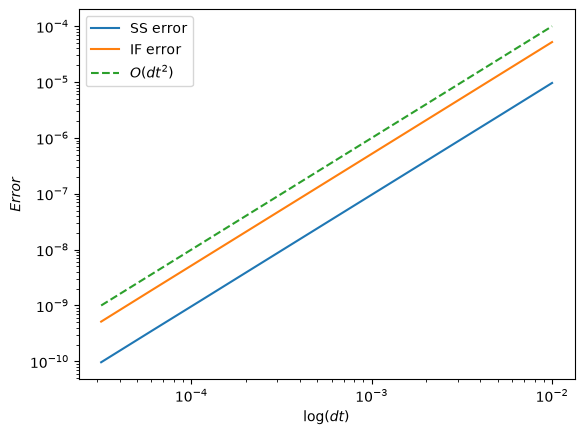

In [9]:
plt.loglog(dt_arr, e_ss, label = "SS error")
plt.loglog(dt_arr, e_if, label = "IF error")
plt.loglog(dt_arr, np.array(dt_arr)**2 ,'--', label = r'$O(dt^2)$')
plt.ylabel(r"$Error$")
plt.xlabel(r"$\log(dt)$")
plt.legend()
plt.show()